In [1]:
import numpy as np

def entropy(y):
    """Calculate entropy of a collection of class labels."""
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()

    return -np.sum(
        probabilities * np.log2(probabilities)
    )

parent = np.array(
    ["Yes"] * 6 + ["No"] * 4
)

group_a = np.array(
    ["Yes"] * 4
)

group_b = np.array(
    ["Yes"] * 2 + ["No"] * 4
)

parent_entropy = entropy(parent)

weighted_child_entropy = (
    len(group_a) / len(parent) * entropy(group_a)
    + len(group_b) / len(parent) * entropy(group_b)
)

information_gain = (
    parent_entropy - weighted_child_entropy
)

print("Parent entropy:", parent_entropy)
print("Group A entropy:", entropy(group_a))
print("Group B entropy:", entropy(group_b))
print("Weighted child entropy:", weighted_child_entropy)
print("Information Gain:", information_gain)

Parent entropy: 0.9709505944546686
Group A entropy: -0.0
Group B entropy: 0.9182958340544896
Weighted child entropy: 0.5509775004326937
Information Gain: 0.4199730940219749


In [2]:
def gini_impurity(y):
    """Calculate Gini impurity for class labels."""
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()

    return 1 - np.sum(probabilities ** 2)


parent_gini = gini_impurity(parent)
group_a_gini = gini_impurity(group_a)
group_b_gini = gini_impurity(group_b)

weighted_child_gini = (
    len(group_a) / len(parent) * group_a_gini
    + len(group_b) / len(parent) * group_b_gini
)

gini_gain = parent_gini - weighted_child_gini

print("Parent Gini:", parent_gini)
print("Group A Gini:", group_a_gini)
print("Group B Gini:", group_b_gini)
print("Weighted child Gini:", weighted_child_gini)
print("Gini reduction:", gini_gain)

Parent Gini: 0.48
Group A Gini: 0.0
Group B Gini: 0.4444444444444444
Weighted child Gini: 0.26666666666666666
Gini reduction: 0.21333333333333332


In [3]:
def weighted_impurity(y_left, y_right, criterion="gini"):
    """Calculate weighted child impurity after a binary split."""

    n_total = len(y_left) + len(y_right)

    if criterion == "gini":
        impurity_fn = gini_impurity
    elif criterion == "entropy":
        impurity_fn = entropy
    else:
        raise ValueError("criterion must be 'gini' or 'entropy'")

    left_weight = len(y_left) / n_total
    right_weight = len(y_right) / n_total

    return (
        left_weight * impurity_fn(y_left)
        + right_weight * impurity_fn(y_right)
    )

In [4]:
def best_split_feature(X_feature, y, criterion="gini"):
    """
    Find the best threshold for one numeric feature.

    Returns:
        best_threshold
        best_gain
    """

    # Sort unique values of the feature
    values = np.unique(X_feature)

    if len(values) < 2:
        return None, 0.0

    # Candidate thresholds are midpoints between adjacent values
    thresholds = (values[:-1] + values[1:]) / 2

    parent_impurity = (
        gini_impurity(y)
        if criterion == "gini"
        else entropy(y)
    )

    best_threshold = None
    best_gain = 0.0

    for threshold in thresholds:
        left_mask = X_feature <= threshold
        right_mask = ~left_mask

        y_left = y[left_mask]
        y_right = y[right_mask]

        child_impurity = weighted_impurity(
            y_left,
            y_right,
            criterion=criterion,
        )

        gain = parent_impurity - child_impurity

        if gain > best_gain:
            best_gain = gain
            best_threshold = threshold

    return best_threshold, best_gain

In [5]:
X_feature = np.array([2.1, 3.5, 4.0, 6.2, 7.8, 8.5])
y_small = np.array([0, 0, 0, 1, 1, 1])

threshold, gain = best_split_feature(
    X_feature,
    y_small,
    criterion="gini",
)

print("Best threshold:", threshold)
print("Best Gini reduction:", gain)

Best threshold: 5.1
Best Gini reduction: 0.5


In [6]:
def best_split(X, y, criterion="gini"):
    """
    Find the best feature and threshold across all features.

    Returns:
        best_feature
        best_threshold
        best_gain
    """

    best_feature = None
    best_threshold = None
    best_gain = 0.0

    for feature_idx in range(X.shape[1]):
        threshold, gain = best_split_feature(
            X[:, feature_idx],
            y,
            criterion=criterion,
        )

        if gain > best_gain:
            best_gain = gain
            best_feature = feature_idx
            best_threshold = threshold

    return best_feature, best_threshold, best_gain

In [7]:
class TreeNode:
    def __init__(
        self,
        prediction,
        feature=None,
        threshold=None,
        left=None,
        right=None,
    ):
        self.prediction = prediction
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right

    @property
    def is_leaf(self):
        return self.left is None and self.right is None

In [8]:
def build_tree(
    X,
    y,
    criterion="gini",
    depth=0,
    max_depth=5,
):
    # Majority class becomes this node's prediction
    classes, counts = np.unique(y, return_counts=True)
    prediction = classes[np.argmax(counts)]

    # Stop if node is pure
    if len(classes) == 1:
        return TreeNode(prediction=prediction)

    # Stop if maximum depth is reached
    if depth >= max_depth:
        return TreeNode(prediction=prediction)

    # Find best split across all features
    feature, threshold, gain = best_split(
        X,
        y,
        criterion=criterion,
    )

    # Stop if no useful split exists
    if feature is None or gain <= 0:
        return TreeNode(prediction=prediction)

    # Split the data
    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    # Build child nodes recursively
    left_child = build_tree(
        X[left_mask],
        y[left_mask],
        criterion=criterion,
        depth=depth + 1,
        max_depth=max_depth,
    )

    right_child = build_tree(
        X[right_mask],
        y[right_mask],
        criterion=criterion,
        depth=depth + 1,
        max_depth=max_depth,
    )

    return TreeNode(
        prediction=prediction,
        feature=feature,
        threshold=threshold,
        left=left_child,
        right=right_child,
    )

In [9]:
X_small = np.array([
    [2.1],
    [3.5],
    [4.0],
    [6.2],
    [7.8],
    [8.5],
])

y_small = np.array([0, 0, 0, 1, 1, 1])

tree = build_tree(
    X_small,
    y_small,
    criterion="gini",
    max_depth=3,
)

print("Root feature:", tree.feature)
print("Root threshold:", tree.threshold)
print("Root prediction:", tree.prediction)
print("Is root a leaf:", tree.is_leaf)

Root feature: 0
Root threshold: 5.1
Root prediction: 0
Is root a leaf: False


In [10]:
def predict_one(node, sample):
    """
    Predict the class for one sample by traversing the tree.
    """

    # Stop when we reach a leaf
    if node.is_leaf:
        return node.prediction

    # Decide which branch to follow
    if sample[node.feature] <= node.threshold:
        return predict_one(node.left, sample)

    return predict_one(node.right, sample)

In [11]:
def predict_tree(tree, X):
    """
    Predict classes for multiple samples.
    """

    predictions = [
        predict_one(tree, sample)
        for sample in X
    ]

    return np.array(predictions)

In [12]:
predictions = predict_tree(tree, X_small)

print("Actual:", y_small)
print("Predicted:", predictions)

print(
    "Correct predictions:",
    np.sum(predictions == y_small),
    "out of",
    len(y_small),
)

print(
    "Accuracy:",
    np.mean(predictions == y_small),
)

Actual: [0 0 0 1 1 1]
Predicted: [0 0 0 1 1 1]
Correct predictions: 6 out of 6
Accuracy: 1.0


In [13]:
new_samples = np.array([
    [3.0],
    [5.0],
    [5.5],
    [9.0],
])

new_predictions = predict_tree(tree, new_samples)

print(new_predictions)

[0 0 1 1]


In [14]:
def best_split_feature(
    X_feature,
    y,
    criterion="gini",
    min_samples_leaf=1,
):
    values = np.unique(X_feature)

    if len(values) < 2:
        return None, 0.0

    thresholds = (values[:-1] + values[1:]) / 2

    parent_impurity = (
        gini_impurity(y)
        if criterion == "gini"
        else entropy(y)
    )

    best_threshold = None
    best_gain = 0.0

    for threshold in thresholds:
        left_mask = X_feature <= threshold
        right_mask = ~left_mask

        # Reject splits with undersized children
        if (
            left_mask.sum() < min_samples_leaf
            or right_mask.sum() < min_samples_leaf
        ):
            continue

        y_left = y[left_mask]
        y_right = y[right_mask]

        child_impurity = weighted_impurity(
            y_left,
            y_right,
            criterion=criterion,
        )

        gain = parent_impurity - child_impurity

        if gain > best_gain:
            best_gain = gain
            best_threshold = threshold

    return best_threshold, best_gain

In [15]:
def best_split(
    X,
    y,
    criterion="gini",
    min_samples_leaf=1,
):
    best_feature = None
    best_threshold = None
    best_gain = 0.0

    for feature_idx in range(X.shape[1]):
        threshold, gain = best_split_feature(
            X[:, feature_idx],
            y,
            criterion=criterion,
            min_samples_leaf=min_samples_leaf,
        )

        if gain > best_gain:
            best_gain = gain
            best_feature = feature_idx
            best_threshold = threshold

    return best_feature, best_threshold, best_gain

In [16]:
def build_tree(
    X,
    y,
    criterion="gini",
    depth=0,
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
):
    classes, counts = np.unique(y, return_counts=True)
    prediction = classes[np.argmax(counts)]

    # Stop if pure
    if len(classes) == 1:
        return TreeNode(prediction=prediction)

    # Stop if maximum depth reached
    if depth >= max_depth:
        return TreeNode(prediction=prediction)

    # Stop if too few samples to split
    if len(y) < min_samples_split:
        return TreeNode(prediction=prediction)

    feature, threshold, gain = best_split(
        X,
        y,
        criterion=criterion,
        min_samples_leaf=min_samples_leaf,
    )

    if feature is None or gain <= 0:
        return TreeNode(prediction=prediction)

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    left_child = build_tree(
        X[left_mask],
        y[left_mask],
        criterion=criterion,
        depth=depth + 1,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
    )

    right_child = build_tree(
        X[right_mask],
        y[right_mask],
        criterion=criterion,
        depth=depth + 1,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
    )

    return TreeNode(
        prediction=prediction,
        feature=feature,
        threshold=threshold,
        left=left_child,
        right=right_child,
    )

In [17]:
tree = build_tree(
    X_small,
    y_small,
    criterion="gini",
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=2,
)

predictions = predict_tree(tree, X_small)

print("Predictions:", predictions)
print("Accuracy:", np.mean(predictions == y_small))

Predictions: [0 0 0 1 1 1]
Accuracy: 1.0


## REAL WORLD DATASET

In [18]:
from sklearn.datasets import load_breast_cancer
import pandas as pd
import numpy as np

dataset = load_breast_cancer()

X = dataset.data
y = dataset.target

feature_names = dataset.feature_names
target_names = dataset.target_names

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", target_names)

X shape: (569, 30)
y shape: (569,)
Classes: ['malignant' 'benign']


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("Train distribution:", np.bincount(y_train))
print("Test distribution:", np.bincount(y_test))

Train: (455, 30)
Test: (114, 30)
Train distribution: [170 285]
Test distribution: [42 72]


In [20]:
scratch_tree = build_tree(
    X_train,
    y_train,
    criterion="gini",
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=2,
)

scratch_train_predictions = predict_tree(
    scratch_tree,
    X_train,
)

scratch_test_predictions = predict_tree(
    scratch_tree,
    X_test,
)

print(
    "Scratch train accuracy:",
    np.mean(scratch_train_predictions == y_train),
)

print(
    "Scratch test accuracy:",
    np.mean(scratch_test_predictions == y_test),
)

Scratch train accuracy: 0.989010989010989
Scratch test accuracy: 0.9473684210526315


In [21]:
from sklearn.tree import DecisionTreeClassifier

sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42,
)

sklearn_tree.fit(X_train, y_train)

sklearn_train_predictions = sklearn_tree.predict(X_train)
sklearn_test_predictions = sklearn_tree.predict(X_test)

print(
    "Sklearn train accuracy:",
    sklearn_tree.score(X_train, y_train),
)

print(
    "Sklearn test accuracy:",
    sklearn_tree.score(X_test, y_test),
)

Sklearn train accuracy: 0.989010989010989
Sklearn test accuracy: 0.9298245614035088


In [22]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
)

print("Scratch Decision Tree")
print(classification_report(
    y_test,
    scratch_test_predictions,
    target_names=target_names,
))

print("Scratch confusion matrix:")
print(confusion_matrix(y_test, scratch_test_predictions))

print("\nSklearn Decision Tree")
print(classification_report(
    y_test,
    sklearn_test_predictions,
    target_names=target_names,
))

print("Sklearn confusion matrix:")
print(confusion_matrix(y_test, sklearn_test_predictions))

Scratch Decision Tree
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

Scratch confusion matrix:
[[39  3]
 [ 3 69]]

Sklearn Decision Tree
              precision    recall  f1-score   support

   malignant       0.89      0.93      0.91        42
      benign       0.96      0.93      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.93      0.93       114
weighted avg       0.93      0.93      0.93       114

Sklearn confusion matrix:
[[39  3]
 [ 5 67]]


In [23]:
depth_results = []

for depth in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        min_samples_leaf=2,
        random_state=42,
    )

    model.fit(X_train, y_train)

    depth_results.append({
        "max_depth": depth,
        "train_accuracy": model.score(X_train, y_train),
        "test_accuracy": model.score(X_test, y_test),
    })

depth_results = pd.DataFrame(depth_results)
display(depth_results)

,max_depth,train_accuracy,test_accuracy
0,1.0,0.923077,0.921053
1,2.0,0.958242,0.894737
2,3.0,0.973626,0.938596
3,4.0,0.989011,0.929825
4,5.0,0.991209,0.903509
5,6.0,0.991209,0.877193
6,8.0,0.991209,0.877193
7,10.0,0.991209,0.877193
8,NaN,0.991209,0.877193


In [24]:
depth_results = []

for depth in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        min_samples_leaf=2,
        random_state=42,
    )

    model.fit(X_train, y_train)

    depth_results.append({
        "max_depth": "None" if depth is None else depth,
        "train_accuracy": model.score(X_train, y_train),
        "test_accuracy": model.score(X_test, y_test),
    })

depth_results = pd.DataFrame(depth_results)
display(depth_results)

,max_depth,train_accuracy,test_accuracy
0,1,0.923077,0.921053
1,2,0.958242,0.894737
2,3,0.973626,0.938596
3,4,0.989011,0.929825
4,5,0.991209,0.903509
5,6,0.991209,0.877193
6,8,0.991209,0.877193
7,10,0.991209,0.877193
8,None,0.991209,0.877193


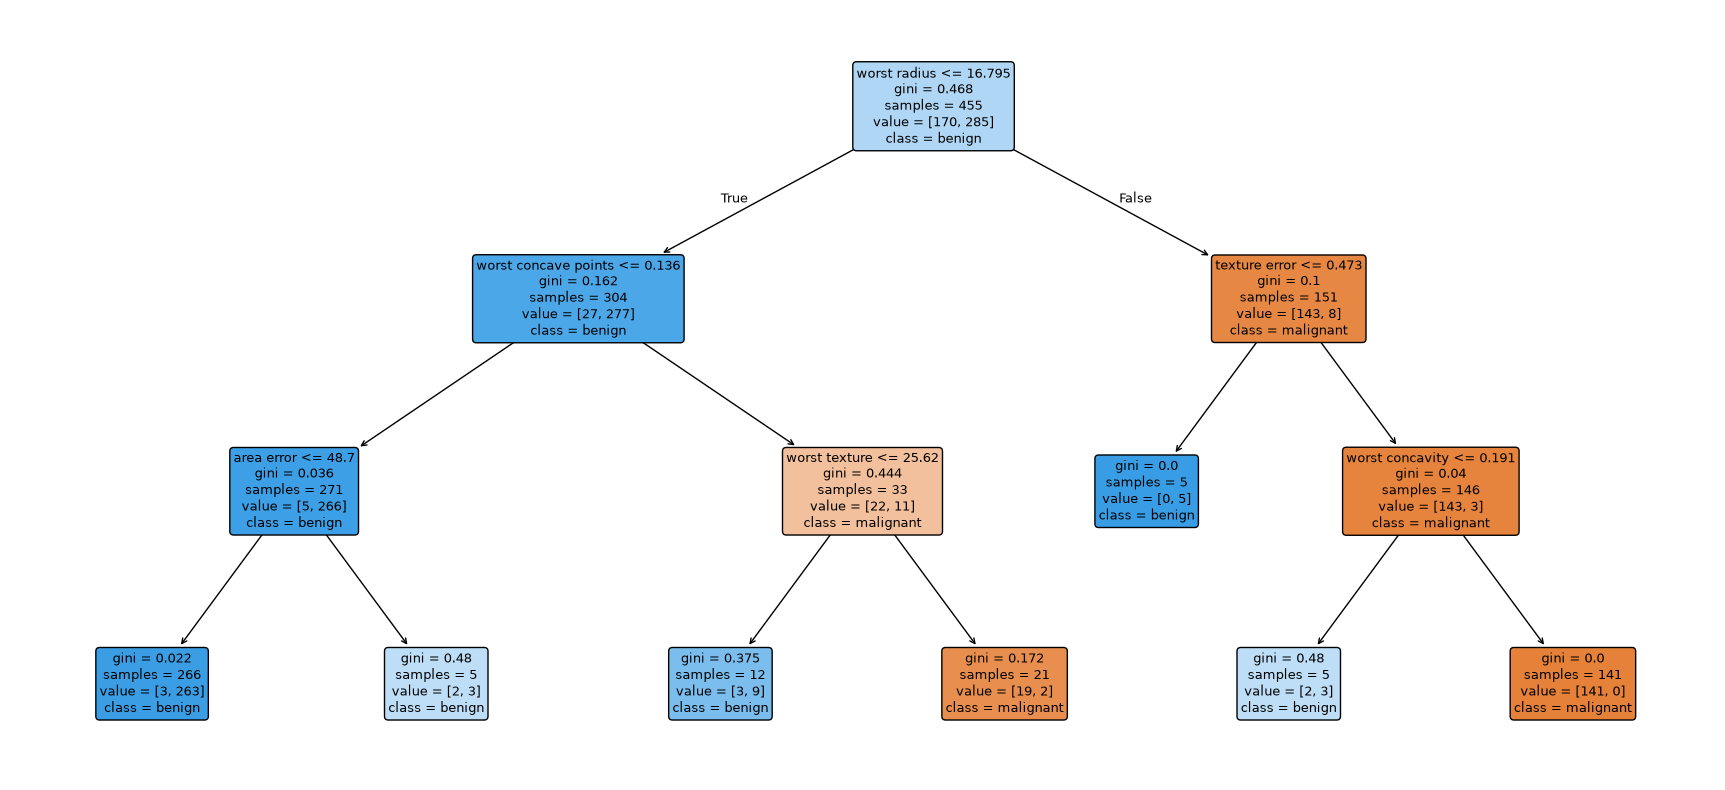

In [25]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

visual_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=2,
    random_state=42,
)

visual_tree.fit(X_train, y_train)

plt.figure(figsize=(22, 10))

plot_tree(
    visual_tree,
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True,
    fontsize=9,
)

plt.show()

In [26]:
import pandas as pd

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": visual_tree.feature_importances_,
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False,
)

display(importance_df.head(10))

,feature,importance
20,worst radius,0.765578
27,worst concave points,0.127356
11,texture error,0.047784
21,worst texture,0.033731
26,worst concavity,0.017911
13,area error,0.007641
5,mean compactness,0.000000
4,mean smoothness,0.000000
6,mean concavity,0.000000
7,mean concave points,0.000000


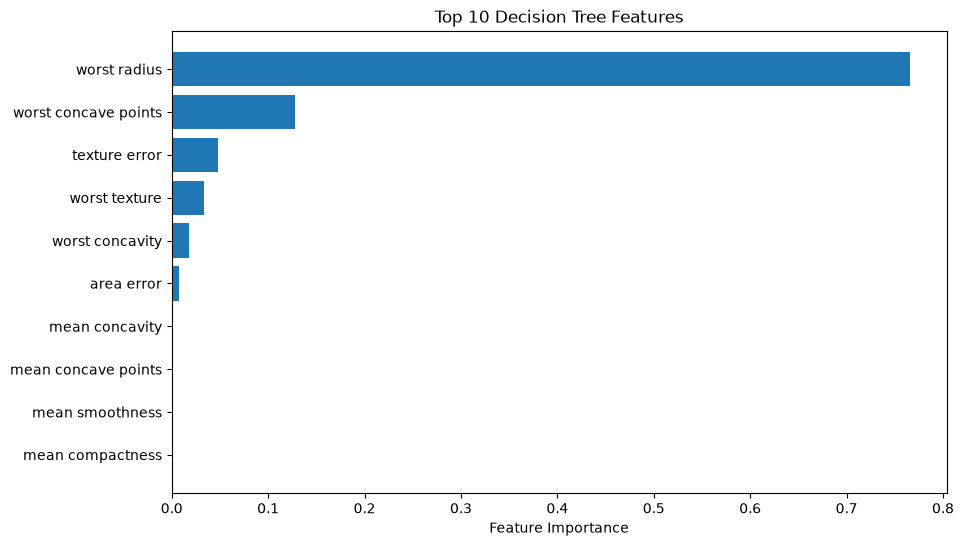

In [27]:
import matplotlib.pyplot as plt

top_features = importance_df.head(10).sort_values("importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"],
    top_features["importance"],
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Decision Tree Features")
plt.show()

In [28]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    visual_tree,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=30,
    random_state=42,
)

permutation_df = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
})

permutation_df = permutation_df.sort_values(
    "importance_mean",
    ascending=False,
)

display(permutation_df.head(10))

,feature,importance_mean,importance_std
26,worst concavity,0.123392,0.019866
20,worst radius,0.083918,0.018770
27,worst concave points,0.080409,0.024716
21,worst texture,0.033333,0.013089
0,mean radius,0.000000,0.000000
1,mean texture,0.000000,0.000000
6,mean concavity,0.000000,0.000000
7,mean concave points,0.000000,0.000000
8,mean symmetry,0.000000,0.000000
9,mean fractal dimension,0.000000,0.000000


In [29]:
from sklearn.tree import DecisionTreeClassifier

base_tree = DecisionTreeClassifier(
    criterion="gini",
    min_samples_leaf=2,
    random_state=42,
)

base_tree.fit(X_train, y_train)

pruning_path = base_tree.cost_complexity_pruning_path(
    X_train,
    y_train,
)

ccp_alphas = pruning_path.ccp_alphas

print("Number of alpha candidates:", len(ccp_alphas))
print(ccp_alphas)

Number of alpha candidates: 13
[0.         0.00109007 0.00175824 0.00286487 0.00426722 0.00502355
 0.00527473 0.00593407 0.00764113 0.01439037 0.02038595 0.05433359
 0.32661707]


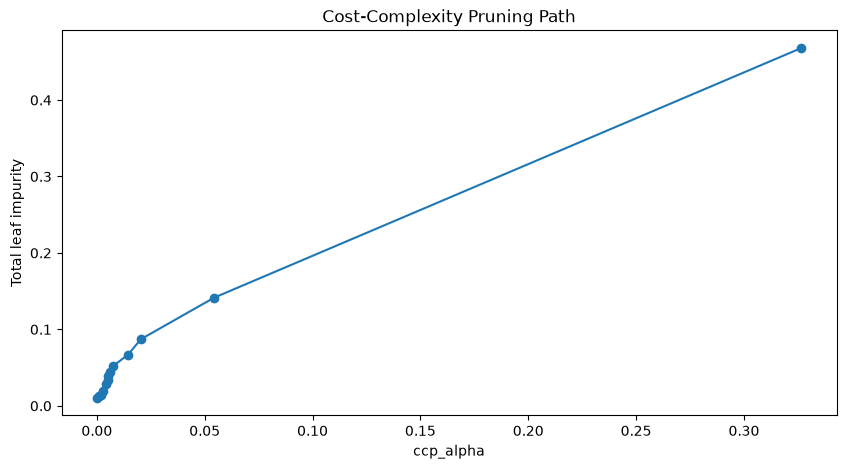

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    ccp_alphas,
    pruning_path.impurities,
    marker="o",
)

plt.xlabel("ccp_alpha")
plt.ylabel("Total leaf impurity")
plt.title("Cost-Complexity Pruning Path")
plt.show()

In [31]:
from sklearn.model_selection import cross_val_score

alpha_results = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        criterion="gini",
        min_samples_leaf=2,
        ccp_alpha=alpha,
        random_state=42,
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
    )

    alpha_results.append({
        "ccp_alpha": alpha,
        "cv_mean_accuracy": scores.mean(),
        "cv_std": scores.std(),
    })

alpha_df = pd.DataFrame(alpha_results)
display(alpha_df.sort_values("cv_mean_accuracy", ascending=False))

,ccp_alpha,cv_mean_accuracy,cv_std
4,0.004267,0.938462,0.016447
3,0.002865,0.938462,0.016447
5,0.005024,0.938462,0.016447
6,0.005275,0.938462,0.016447
7,0.005934,0.936264,0.012815
8,0.007641,0.936264,0.012815
2,0.001758,0.931868,0.018906
10,0.020386,0.927473,0.028317
9,0.014390,0.925275,0.025441
1,0.001090,0.918681,0.017855


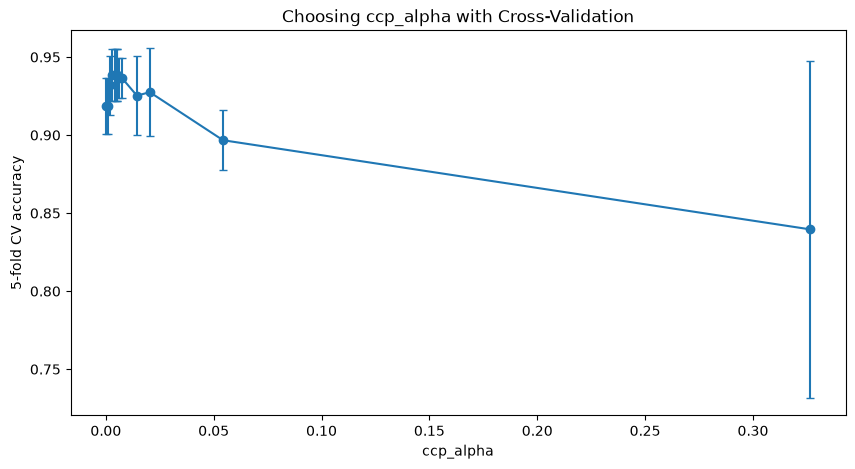

In [32]:
plt.figure(figsize=(10, 5))

plt.errorbar(
    alpha_df["ccp_alpha"],
    alpha_df["cv_mean_accuracy"],
    yerr=alpha_df["cv_std"],
    marker="o",
    capsize=3,
)

plt.xlabel("ccp_alpha")
plt.ylabel("5-fold CV accuracy")
plt.title("Choosing ccp_alpha with Cross-Validation")
plt.show()

In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

selected_alpha = 0.02038595

pruned_tree = DecisionTreeClassifier(
    criterion="gini",
    min_samples_leaf=2,
    ccp_alpha=selected_alpha,
    random_state=42,
)

pruned_tree.fit(X_train, y_train)

y_pred_pruned = pruned_tree.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_pruned))
print("Tree depth:", pruned_tree.get_depth())
print("Number of leaves:", pruned_tree.get_n_leaves())

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_pruned))

print("\nClassification report:")
print(classification_report(y_test, y_pred_pruned, target_names=target_names))

Test accuracy: 0.9035087719298246
Tree depth: 2
Number of leaves: 3

Confusion matrix:
[[41  1]
 [10 62]]

Classification report:
              precision    recall  f1-score   support

   malignant       0.80      0.98      0.88        42
      benign       0.98      0.86      0.92        72

    accuracy                           0.90       114
   macro avg       0.89      0.92      0.90       114
weighted avg       0.92      0.90      0.90       114

